# 01 · Unimodal fits

The auditory task (two noise levels) and the visual task. Each participant gets a lognormal psychometric function in log(test/standard) with a shared lapse rate:
- **σ per condition:** the discrimination noise of two intervals. The single-interval noise used to fix the models is σ/√2.
- **μ fixed at 0:** as in the paper.
- **Free-μ check:** a second fit with μ free shows any time-order or interval bias, which ought to be near zero.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
ROOT = Path.cwd().resolve().parent                      # av_dur_experiment_v2/
sys.path[:0] = [str(ROOT), str(ROOT.parent)]            # experiment code + repository (plot_style.py)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
try:
    from plot_style import *                            # shared figure style of the repository
except ImportError:
    FONT_SIZE_LABEL, FONT_SIZE_TITLE = 14, 16
    def add_panel_labels(*a, **k): pass

import experiment_settings as S
from avdur import storage, psychometrics as pm, bias as bias_mod

DATA_ROOT = ROOT / 'data'                 # real participants
# DATA_ROOT = ROOT / 'data_test'         # runs with a testing-only monitor profile (e.g. office_test)
if not storage.sessions(root=DATA_ROOT):      # no completed session yet
    DATA_ROOT = ROOT / 'data_simulated'
    print('No completed sessions in data/ yet: showing SIMULATED participants (python tests/test_pipeline.py).')
print('Data folder:', DATA_ROOT, '| participants:', storage.participants(DATA_ROOT))

No completed sessions in data/ yet: showing SIMULATED participants (python tests/test_pipeline.py).
Data folder: /Users/ofy204/Documents/my_repos/av-dur-estimation/av_dur_experiment_v2/data_simulated | participants: ['SIM01', 'SIM02', 'SIM75']


In [2]:
def binned(df, x_col='x', n_bins=8):
    d = df.copy()
    d['bin'] = pd.qcut(d[x_col], n_bins, duplicates='drop')
    return d.groupby('bin', observed=True).agg(x=(x_col, 'mean'), p=('chose_test', 'mean'), n=('chose_test', 'size'))

def order_balance(df, keys):
    t = df.groupby(keys + ['order']).size().unstack(fill_value=0)
    t['test-second share'] = (t.get(2, 0) / t.sum(axis=1)).round(2)
    return t

In [3]:
aud = storage.load_trials('unimodal_auditory', root=DATA_ROOT)
vis = storage.load_trials('unimodal_visual', root=DATA_ROOT)
print(f'auditory: {len(aud)} trials, visual: {len(vis)} trials')
display(order_balance(aud, ['participantID', 'audNoise']))
display(order_balance(vis, ['participantID']))

auditory: 616 trials, visual: 308 trials


order                    1   2  test-second share
participantID audNoise                           
SIM01         0.1       77  77                0.5
              1.2       77  77                0.5
SIM02         0.1       77  77                0.5
              1.2       77  77                0.5

order,1,2,test-second share
participantID,,,
SIM01,77,77,0.5
SIM02,77,77,0.5


## Fits

In [4]:
rows = []
for task, df, cond in [('auditory', aud, 'audNoise'), ('visual', vis.assign(cond='visual'), 'cond')]:
    for pid, d in df.groupby('participantID'):
        fixed = pm.fit(d, cond, 'lognormal', lapse_max=0.25, mu_fixed=0.0)
        free = pm.fit(d, cond, 'lognormal', lapse_max=0.25)
        for (_, f), (_, g) in zip(fixed['params'].iterrows(), free['params'].iterrows()):
            rows.append(dict(task=task, participant=pid, condition=f.condition, n=f.n, sigma=f.sigma,
                             sigma_single_interval=f.sigma / np.sqrt(2), lapse=f.lapse,
                             mu_free=g.mu, flags=', '.join(fixed['at_bound']) or ''))
fits = pd.DataFrame(rows)
fits.round(3)

,task,participant,condition,n,sigma,sigma_single_interval,lapse,mu_free,flags
0,auditory,SIM01,0.1,154.0,0.057,0.041,0.048,0.009,
1,auditory,SIM01,1.2,154.0,0.350,0.247,0.048,-0.037,
2,auditory,SIM02,0.1,154.0,0.202,0.143,0.033,0.032,
3,auditory,SIM02,1.2,154.0,0.624,0.441,0.033,-0.139,
4,visual,SIM01,visual,154.0,0.339,0.240,0.056,0.011,
5,visual,SIM02,visual,154.0,0.431,0.305,0.000,0.047,


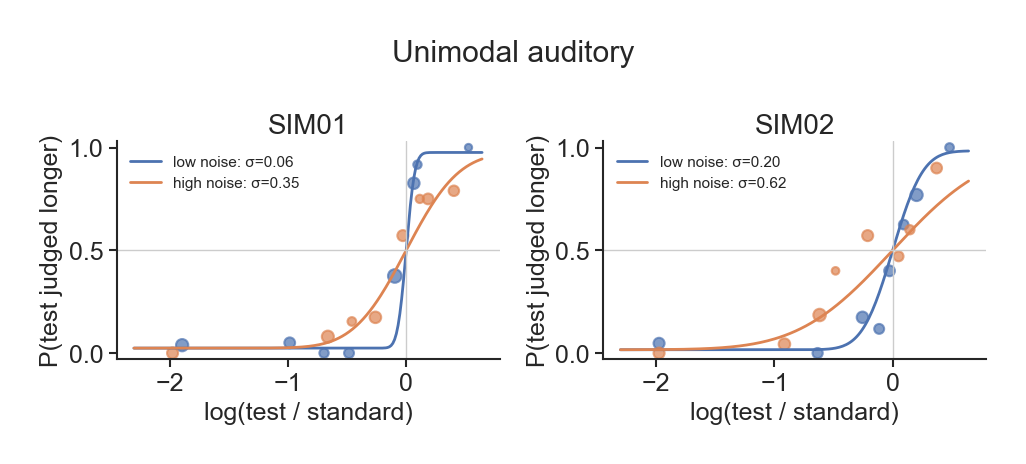

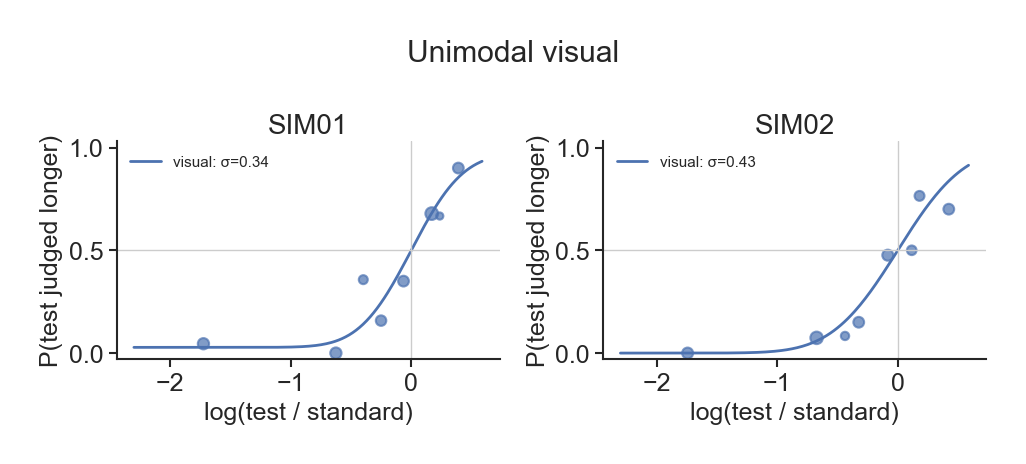

In [5]:
def plot_task(df, cond_col, labels, title):
    pids = sorted(df.participantID.unique())
    fig, axes = plt.subplots(1, len(pids), figsize=(5 * len(pids), 4.2), squeeze=False)
    for ax, pid in zip(axes[0], pids):
        d = df[df.participantID == pid].copy()
        d['x'] = np.log(d.testDurS / d.standardDur)
        fit = pm.fit(d, cond_col, 'lognormal', lapse_max=0.25, mu_fixed=0.0)['params'].set_index('condition')
        xs = np.linspace(d.x.min(), d.x.max(), 200)
        for k, (c, label) in enumerate(labels.items()):
            dc = d[d[cond_col] == c]
            if dc.empty:
                continue
            b = binned(dc)
            color = sns.color_palette('deep')[k]
            ax.scatter(b.x, b.p, s=b.n * 3, color=color, alpha=0.7)
            ax.plot(xs, pm.predict(xs, 0.0, fit.loc[c, 'sigma'], fit.loc[c, 'lapse']), color=color,
                    label=f"{label}: σ={fit.loc[c, 'sigma']:.2f}")
        ax.axhline(0.5, color='0.8', lw=1); ax.axvline(0, color='0.8', lw=1)
        ax.set(title=pid, xlabel='log(test / standard)', ylabel='P(test judged longer)', ylim=(-0.03, 1.03))
        ax.legend(fontsize=11, frameon=False, loc='upper left')
        sns.despine(ax=ax)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

plot_task(aud, 'audNoise', {0.1: 'low noise', 1.2: 'high noise'}, 'Unimodal auditory')
plot_task(vis.assign(cond='visual'), 'cond', {'visual': 'visual'}, 'Unimodal visual')

## Timing check, visual task

Logged flip-to-flip durations minus intended durations. Both should sit within a frame (8.3 ms) in both orders. v1 never logged these.

In [6]:
v = vis.copy()
v['test_error_ms'] = 1000 * (v.recordedDurVisualTest - v.intendedDurVisualTest)
v['standard_error_ms'] = 1000 * (v.recordedDurVisualStandard - v.intendedDurVisualStandard)
v.groupby(['participantID', 'order'])[['test_error_ms', 'standard_error_ms', 'n_dropped_frames']].agg(['median', 'max']).round(1)

test_error_ms      standard_error_ms       \
                           median  max            median  max   
participantID order                                             
SIM01         1              -0.1  0.9               0.1  0.9   
              2              -0.1  1.0               0.0  1.3   
SIM02         1               0.1  0.9               0.0  1.3   
              2               0.0  1.1              -0.0  1.1   

                    n_dropped_frames      
                              median max  
participantID order                       
SIM01         1                  0.0   0  
              2                  0.0   0  
SIM02         1                  0.0   0  
              2                  0.0   0